# 01. Khám phá Dữ liệu Thô & Thống kê Chất lượng Bình luận (Pre-Cleaning EDA)

Notebook này thực hiện kiểm toán chất lượng dữ liệu thô (**Raw Data Quality Profiling**) trên cả 3 nguồn thu thập (**Tiki**, **Google Play**, **App Store**) thông qua module `src.processing.raw_data_quality_stats` **trước khi** đưa vào bước làm sạch (`data_cleaner.py`) và gán nhãn cảm xúc (`nlp_pipeline.py`).

Mỗi cell dưới đây đảm nhận đúng 1 nhiệm vụ độc lập (Single Responsibility Principle) để dễ dàng chạy lại và trích xuất biểu đồ đưa vào báo cáo đồ án.

In [1]:
# Cell 1: Thiết lập đường dẫn hệ thống và nạp thư viện trực quan hóa
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.processing.raw_data_quality_stats import (
    load_raw_dataset,
    profile_single_source,
    print_pretty_report,
)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
plt.rcParams['axes.unicode_minus'] = False
FIGURES_DIR = PROJECT_ROOT / 'data' / 'gold_processed' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f'[+] Đã khởi tạo môi trường EDA. Thư mục lưu ảnh báo cáo: {FIGURES_DIR}')

[+] Đã khởi tạo môi trường EDA. Thư mục lưu ảnh báo cáo: data/gold_processed/figures


In [2]:
# Cell 2: Nạp dữ liệu thô từ 3 nguồn (Tiki, Google Play, App Store) và in bảng thống kê tổng hợp
RAW_SOURCES = [
    ('Tiki', PROJECT_ROOT / 'data' / 'raw' / 'ecommerce_reviews' / 'tiki.csv'),
    ('Google Play', PROJECT_ROOT / 'data' / 'raw' / 'mobile_reviews' / 'google_play.csv'),
    ('App Store', PROJECT_ROOT / 'data' / 'raw' / 'mobile_reviews' / 'app_store.csv'),
]

reports = []
for label, path in RAW_SOURCES:
    if path.exists():
        df_raw = load_raw_dataset(path)
        reports.append(profile_single_source(df_raw, label))
    else:
        print(f'[!] Chưa tìm thấy file {path}, vui lòng kiểm tra lại đường dẫn.')

df_summary = print_pretty_report(reports)
display(df_summary)

1. BẢNG TỔNG HỢP CHẤT LƯỢNG DỮ LIỆU THÔ TOÀN HỆ THỐNG:
      Nguồn dữ liệu  Tổng số dòng Comment = Null Có nội dung chữ Language = Null Trùng nội dung  Chỉ Emoji/Số/Ký tự  Cụt lủn 1 từ  Ngắn 2 từ  Spam/Loạn phím  3-5* nhưng chê Số từ TB (Median)
               Tiki          2300  1629 (70.83%)    671 (29.17%)   2300 (100.0%)    80 (11.92%)                   6            86         50               3              35       12.34 (7.0)
        Google Play          2000       0 (0.0%)   2000 (100.0%)        0 (0.0%)    398 (19.9%)                  15           403        242              44              44       11.96 (6.0)
          App Store           250       0 (0.0%)    250 (100.0%)    250 (100.0%)      22 (8.8%)                   5            28         32               7               6       13.29 (9.0)
TỔNG CỘNG (3 NGUỒN)          4550   1629 (35.8%)    2921 (64.2%)   2550 (56.04%)   500 (17.12%)                  26           517        324              54              85         

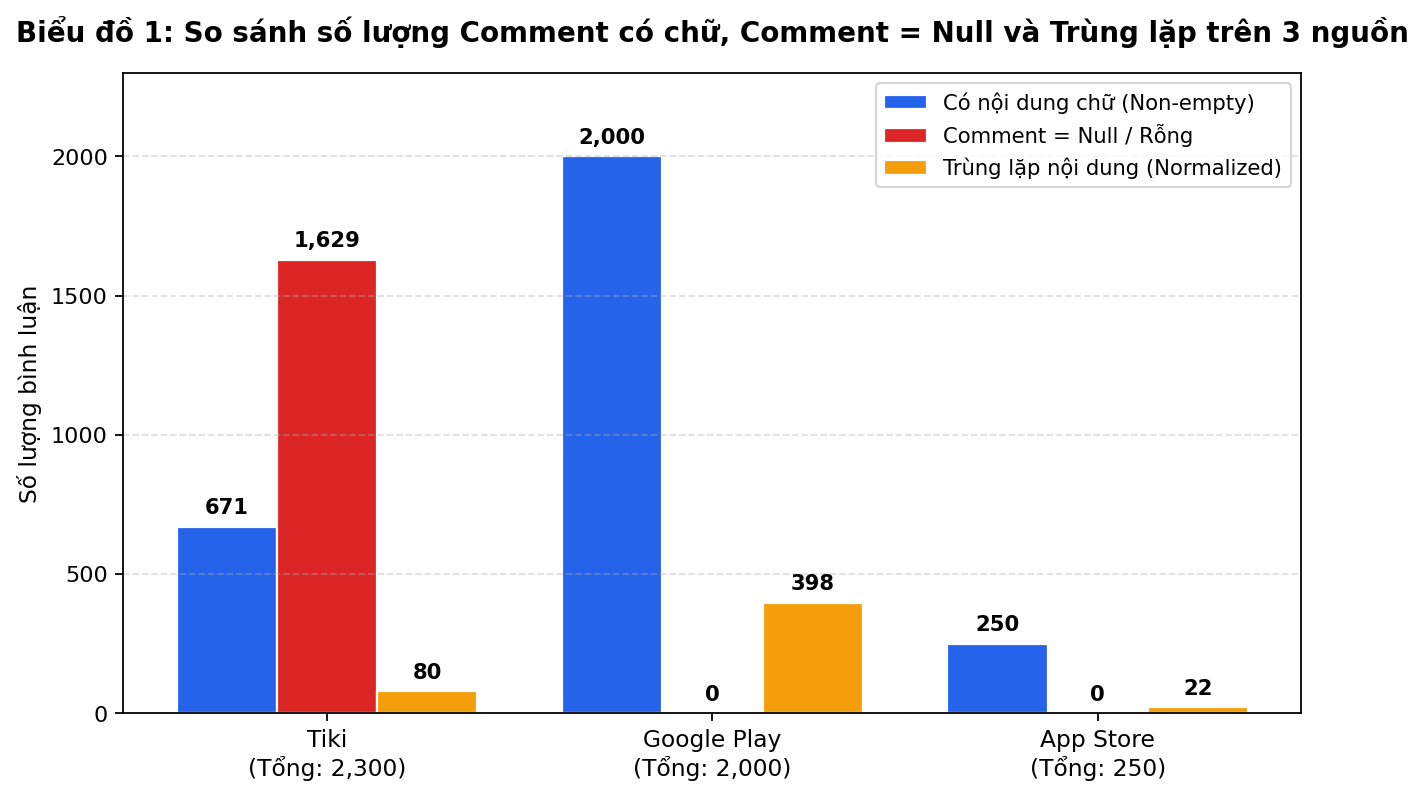

In [3]:
# Cell 3: Biểu đồ 1 - So sánh số lượng Comment có chữ, Comment = Null và Trùng lặp trên 3 nguồn
fig1, ax1 = plt.subplots(figsize=(9.5, 5.2))
sources = [r['source_label'] for r in reports]
non_empty = [r['non_empty_comments_count'] for r in reports]
null_counts = [r['null_comments_count'] for r in reports]
dup_counts = [r['duplicate_content_norm_count'] for r in reports]

x = np.arange(len(sources))
w = 0.26
b1 = ax1.bar(x - w, non_empty, width=w, label='Có nội dung chữ (Non-empty)', color='#2563eb', edgecolor='white')
b2 = ax1.bar(x, null_counts, width=w, label='Comment = Null / Rỗng', color='#dc2626', edgecolor='white')
b3 = ax1.bar(x + w, dup_counts, width=w, label='Trùng lặp nội dung (Normalized)', color='#f59e0b', edgecolor='white')

for bars in (b1, b2, b3):
    for bar in bars:
        h = int(bar.get_height())
        ax1.annotate(f'{h:,}', xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 4), textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')

ax1.set_title('Biểu đồ 1: So sánh số lượng Comment có chữ, Comment = Null và Trùng lặp trên 3 nguồn', fontsize=12.5, fontweight='bold', pad=14)
ax1.set_xticks(x)
ax1.set_xticklabels([f"{r['source_label']}\n(Tổng: {r['total_rows']:,})" for r in reports], fontsize=10.5)
ax1.set_ylabel('Số lượng bình luận', fontsize=10.5)
ax1.set_ylim(0, max(non_empty + null_counts) * 1.15)
ax1.grid(axis='y', linestyle='--', alpha=0.4)
ax1.legend(frameon=True, fontsize=9.5)
fig1.savefig(FIGURES_DIR / '01_completeness_and_duplicates.png', dpi=200, bbox_inches='tight')
plt.show()

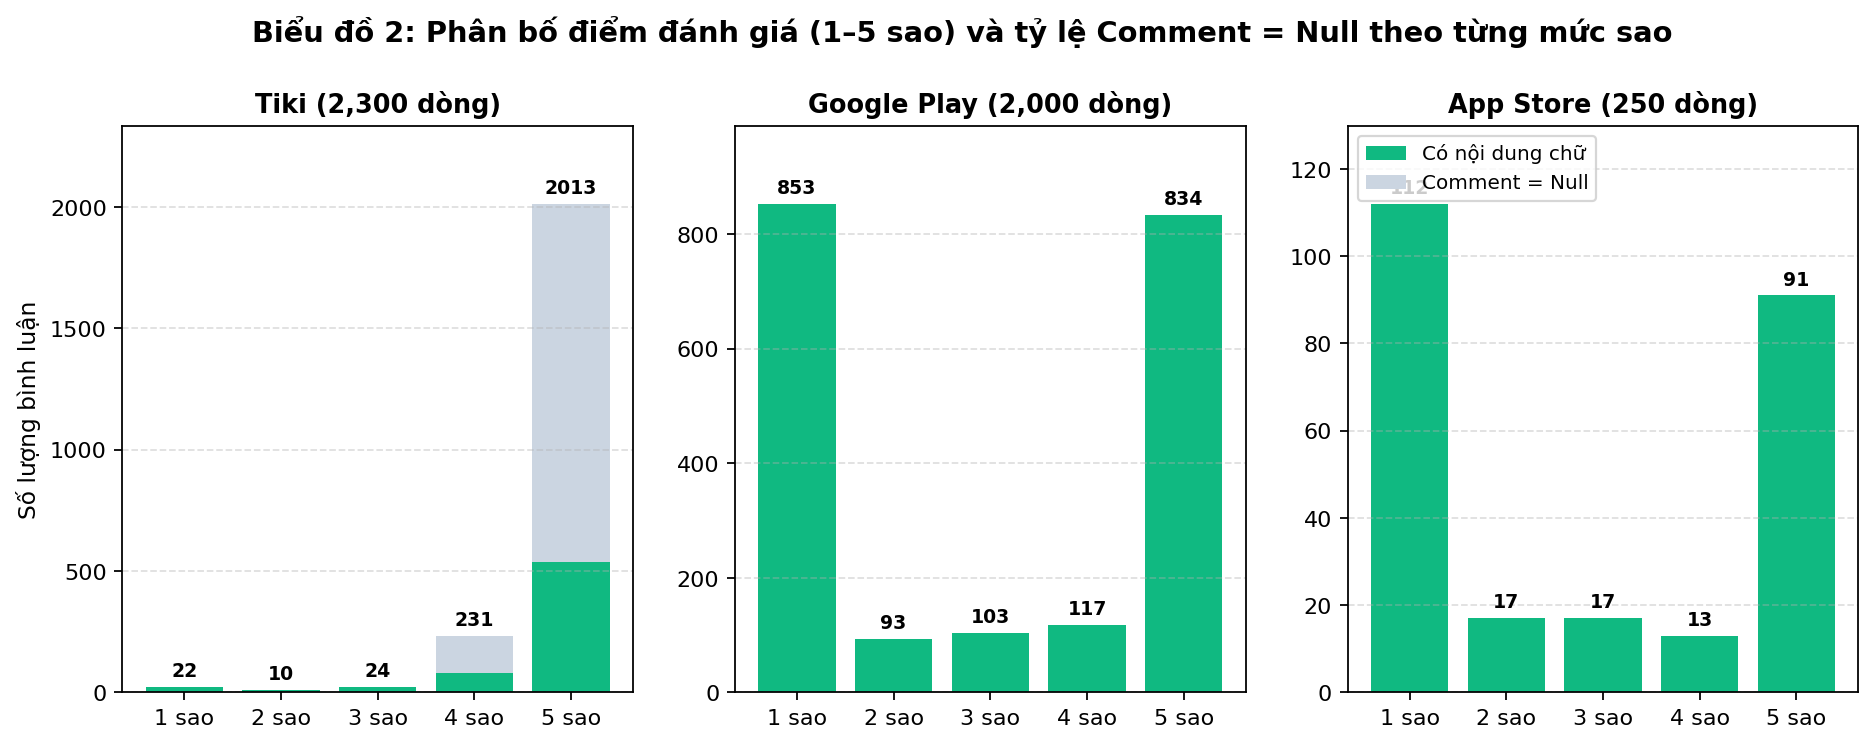

In [4]:
# Cell 4: Biểu đồ 2 - Phân bố điểm đánh giá (1-5 sao) và tỷ lệ Comment = Null theo từng mức sao
fig2, axes2 = plt.subplots(1, 3, figsize=(14, 4.6), sharey=False)
for idx, rep in enumerate(reports):
    ax = axes2[idx]
    stars = [1, 2, 3, 4, 5]
    has_txt = [rep['rating_breakdown'][s]['non_empty'] if s in rep['rating_breakdown'] else rep['rating_breakdown'][str(s)]['non_empty'] for s in stars]
    is_null = [rep['rating_breakdown'][s]['null_or_empty'] if s in rep['rating_breakdown'] else rep['rating_breakdown'][str(s)]['null_or_empty'] for s in stars]
    ax.bar(stars, has_txt, label='Có nội dung chữ', color='#10b981')
    ax.bar(stars, is_null, bottom=has_txt, label='Comment = Null', color='#cbd5e1')
    for s_i, (ht, nl) in enumerate(zip(has_txt, is_null)):
        tot = ht + nl
        if tot > 0:
            ax.annotate(f'{tot}', xy=(stars[s_i], tot), xytext=(0, 3),
                        textcoords='offset points', ha='center', va='bottom', fontsize=8.5, fontweight='bold')
    ax.set_title(f"{rep['source_label']} ({rep['total_rows']:,} dòng)", fontsize=11.5, fontweight='bold')
    ax.set_xticks(stars)
    ax.set_xticklabels([f'{s} sao' for s in stars])
    ax.set_ylim(0, max(h + n for h, n in zip(has_txt, is_null)) * 1.16)
    ax.grid(axis='y', linestyle='--', alpha=0.4)
    if idx == 0:
        ax.set_ylabel('Số lượng bình luận', fontsize=10.5)
    if idx == 2:
        ax.legend(loc='upper left', fontsize=9)
fig2.suptitle('Biểu đồ 2: Phân bố điểm đánh giá (1–5 sao) và tỷ lệ Comment = Null theo từng mức sao', fontsize=13, fontweight='bold', y=1.03)
fig2.savefig(FIGURES_DIR / '02_star_rating_distribution.png', dpi=200, bbox_inches='tight')
plt.show()

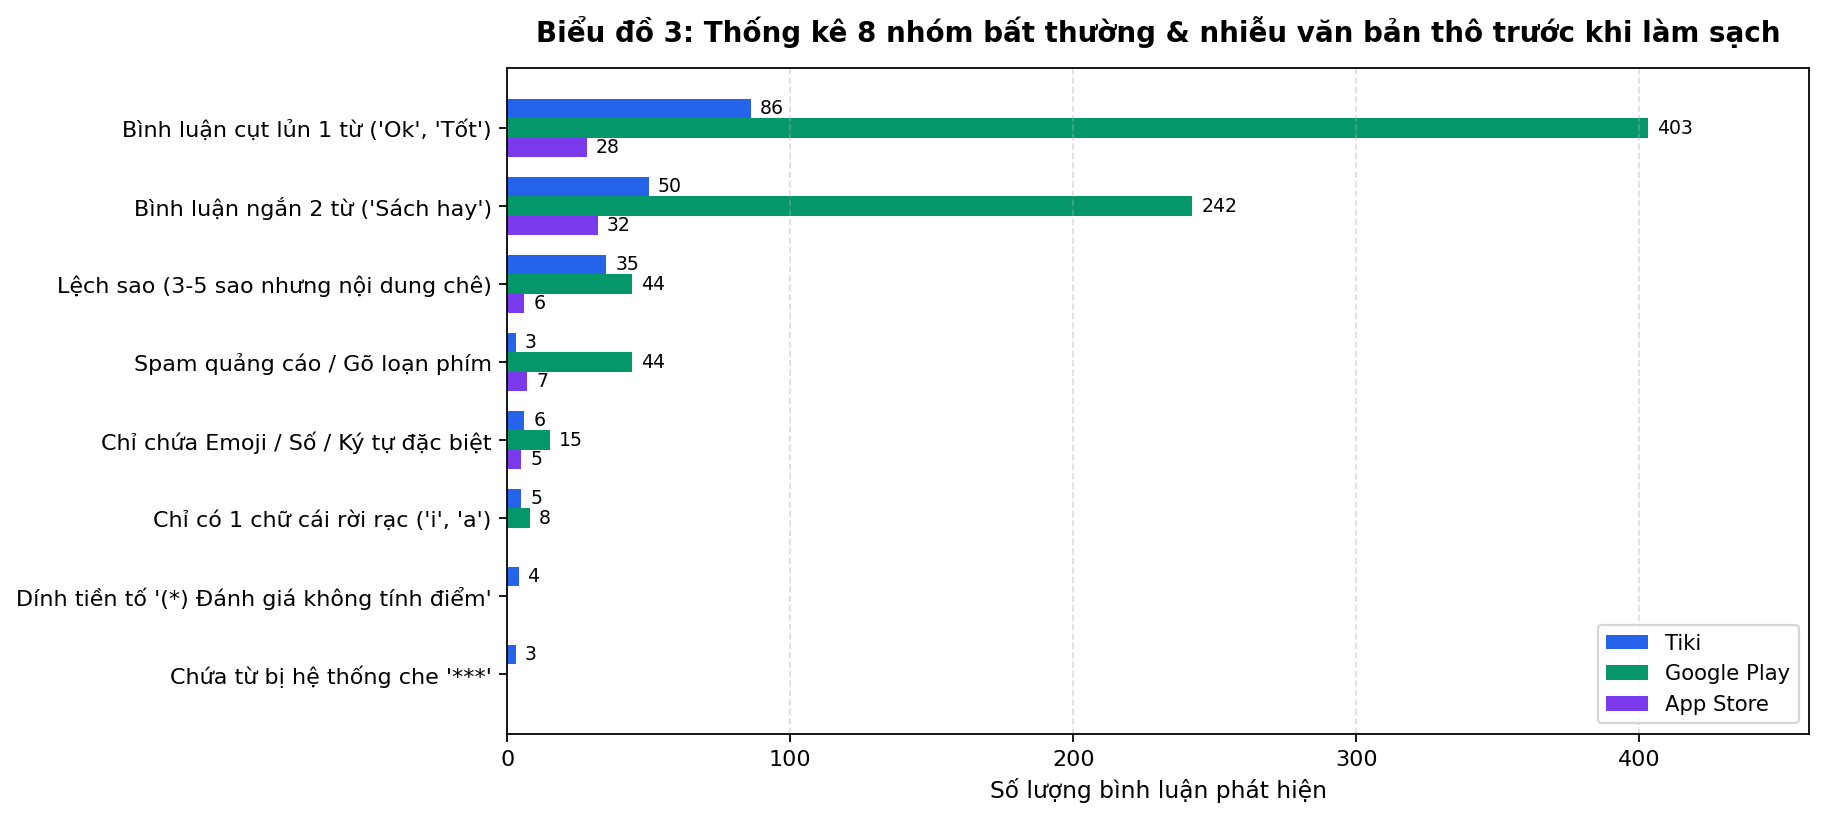

In [5]:
# Cell 5: Biểu đồ 3 - Thống kê 8 nhóm bất thường & nhiễu văn bản thô trước khi làm sạch
fig3, ax3 = plt.subplots(figsize=(10.5, 5.4))
anomaly_keys = [
    ('one_word_comments', "Bình luận cụt lủn 1 từ ('Ok', 'Tốt')"),
    ('two_word_comments', "Bình luận ngắn 2 từ ('Sách hay')"),
    ('star_3_to_5_with_complaint_text', 'Lệch sao (3-5 sao nhưng nội dung chê)'),
    ('suspected_spam_or_gibberish', 'Spam quảng cáo / Gõ loạn phím'),
    ('no_alpha_emoji_or_symbol_only', 'Chỉ chứa Emoji / Số / Ký tự đặc biệt'),
    ('single_alpha_char_only', "Chỉ có 1 chữ cái rời rạc ('i', 'a')"),
    ('tiki_system_prefix_no_score', "Dính tiền tố '(*) Đánh giá không tính điểm'"),
    ('censored_asterisks', "Chứa từ bị hệ thống che '***'"),
]
y_pos = np.arange(len(anomaly_keys))
colors_src = ['#2563eb', '#059669', '#7c3aed']
bar_h = 0.25

for s_idx, rep in enumerate(reports):
    vals = [rep['anomalies'][k] for k, _ in anomaly_keys]
    bars = ax3.barh(y_pos + (s_idx - 1) * bar_h, vals, height=bar_h, label=rep['source_label'], color=colors_src[s_idx])
    for bar in bars:
        w_val = int(bar.get_width())
        if w_val > 0:
            ax3.annotate(f'{w_val}', xy=(w_val, bar.get_y() + bar.get_height() / 2),
                         xytext=(4, 0), textcoords='offset points', ha='left', va='center', fontsize=8.5)

ax3.set_yticks(y_pos)
ax3.set_yticklabels([label for _, label in anomaly_keys], fontsize=10)
ax3.invert_yaxis()
ax3.set_xlabel('Số lượng bình luận phát hiện', fontsize=10.5)
ax3.set_xlim(0, 460)
ax3.set_title('Biểu đồ 3: Thống kê 8 nhóm bất thường & nhiễu văn bản thô trước khi làm sạch', fontsize=12.5, fontweight='bold', pad=12)
ax3.grid(axis='x', linestyle='--', alpha=0.4)
ax3.legend(loc='lower right', fontsize=9.5)
fig3.savefig(FIGURES_DIR / '03_raw_text_anomalies.png', dpi=200, bbox_inches='tight')
plt.show()

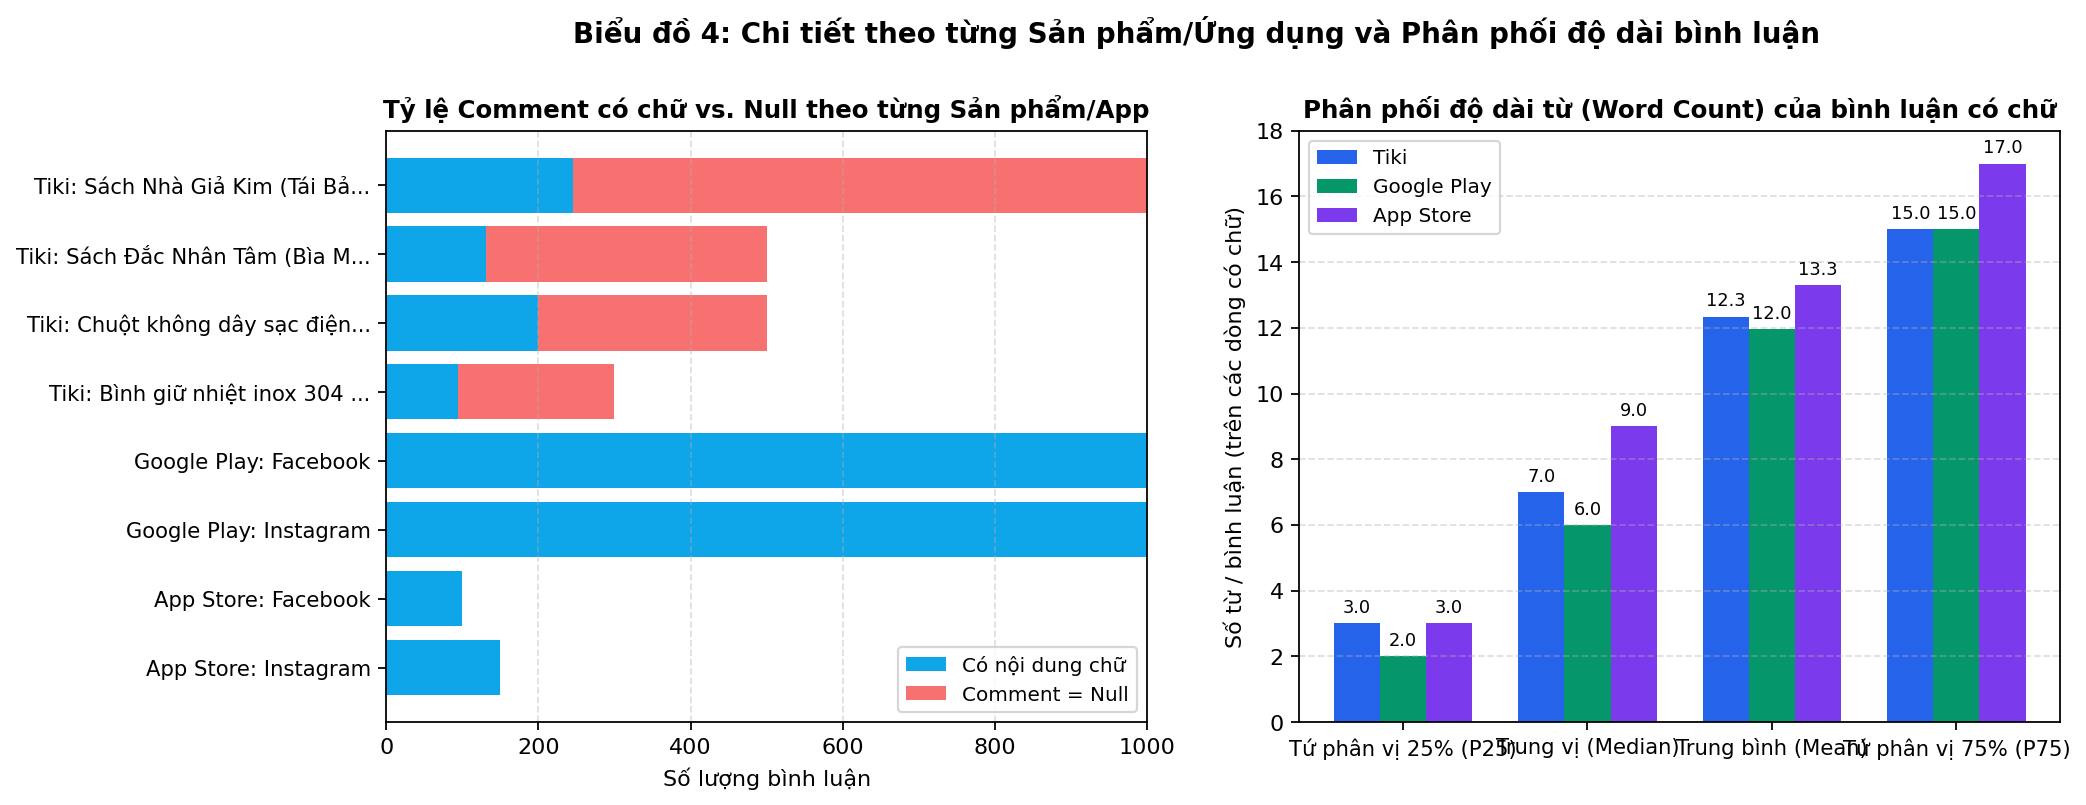

In [6]:
# Cell 6: Biểu đồ 4 - Chi tiết theo từng Sản phẩm/App và Phân phối độ dài bình luận (Word Count)
fig4, (ax4a, ax4b) = plt.subplots(1, 2, figsize=(13.5, 4.8))
all_items = []
for rep in reports:
    for it in rep['item_breakdown']:
        short_name = it['item_name'][:24] + ('...' if len(it['item_name']) > 24 else '')
        all_items.append((f"{rep['source_label']}: {short_name}", it['non_empty_rows'], it['null_or_empty_rows']))

y_it = np.arange(len(all_items))
it_labels = [x[0] for x in all_items]
it_valid = [x[1] for x in all_items]
it_null = [x[2] for x in all_items]

ax4a.barh(y_it, it_valid, label='Có nội dung chữ', color='#0ea5e9')
ax4a.barh(y_it, it_null, left=it_valid, label='Comment = Null', color='#f87171')
ax4a.set_yticks(y_it)
ax4a.set_yticklabels(it_labels, fontsize=9.5)
ax4a.invert_yaxis()
ax4a.set_xlabel('Số lượng bình luận', fontsize=10)
ax4a.set_title('Tỷ lệ Comment có chữ vs. Null theo từng Sản phẩm/App', fontsize=11, fontweight='bold')
ax4a.grid(axis='x', linestyle='--', alpha=0.4)
ax4a.legend(fontsize=9)

metrics_labels = ['Tứ phân vị 25% (P25)', 'Trung vị (Median)', 'Trung bình (Mean)', 'Tứ phân vị 75% (P75)']
x_m = np.arange(len(metrics_labels))
for s_idx, rep in enumerate(reports):
    wc = rep['word_count_stats']
    m_vals = [wc['p25'], wc['median'], wc['mean'], wc['p75']]
    bars = ax4b.bar(x_m + (s_idx - 1) * 0.25, m_vals, width=0.25, label=rep['source_label'], color=colors_src[s_idx])
    for bar in bars:
        v = bar.get_height()
        ax4b.annotate(f'{v:.1f}', xy=(bar.get_x() + bar.get_width() / 2, v),
                      xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=8)

ax4b.set_xticks(x_m)
ax4b.set_xticklabels(metrics_labels, fontsize=9.5)
ax4b.set_ylabel('Số từ / bình luận (trên các dòng có chữ)', fontsize=10)
ax4b.set_ylim(0, 18)
ax4b.set_title('Phân phối độ dài từ (Word Count) của bình luận có chữ', fontsize=11, fontweight='bold')
ax4b.grid(axis='y', linestyle='--', alpha=0.4)
ax4b.legend(fontsize=9)
fig4.suptitle('Biểu đồ 4: Chi tiết theo từng Sản phẩm/Ứng dụng và Phân phối độ dài bình luận', fontsize=12.5, fontweight='bold', y=1.03)
fig4.savefig(FIGURES_DIR / '04_item_breakdown_and_word_count.png', dpi=200, bbox_inches='tight')
plt.show()